In [458]:
file_string = open('names.txt','r').read()

In [459]:
names = file_string.split('\n')

In [460]:
names

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn',
 'abigail',
 'emily',
 'elizabeth',
 'mila',
 'ella',
 'avery',
 'sofia',
 'camila',
 'aria',
 'scarlett',
 'victoria',
 'madison',
 'luna',
 'grace',
 'chloe',
 'penelope',
 'layla',
 'riley',
 'zoey',
 'nora',
 'lily',
 'eleanor',
 'hannah',
 'lillian',
 'addison',
 'aubrey',
 'ellie',
 'stella',
 'natalie',
 'zoe',
 'leah',
 'hazel',
 'violet',
 'aurora',
 'savannah',
 'audrey',
 'brooklyn',
 'bella',
 'claire',
 'skylar',
 'lucy',
 'paisley',
 'everly',
 'anna',
 'caroline',
 'nova',
 'genesis',
 'emilia',
 'kennedy',
 'samantha',
 'maya',
 'willow',
 'kinsley',
 'naomi',
 'aaliyah',
 'elena',
 'sarah',
 'ariana',
 'allison',
 'gabriella',
 'alice',
 'madelyn',
 'cora',
 'ruby',
 'eva',
 'serenity',
 'autumn',
 'adeline',
 'hailey',
 'gianna',
 'valentina',
 'isla',
 'eliana',
 'quinn',
 'nevaeh',
 'ivy',
 'sadie',
 'piper',
 'lydia',
 'alexa',
 'josephine',
 'emery',
 'julia'

In [461]:
# Make a set of all unique characters along with the special characters. Remove the newline
chars = set(list(file_string))
chars.remove('\n')

# Turning the set into a list so the structure can be ordered
chars = sorted(list(chars))
chars.insert(0, '.')

In [462]:
chars

['.',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [463]:
# Create a bigram counter for consecutive letters with special start(^) and end($) characters
import torch
A = torch.ones(len(chars), len(chars), dtype=torch.int32)
ctoi = { c:i for i,c in enumerate(chars) }
itoc = { i:c for c,i in ctoi.items() }

val = None
for x in names:
    n = ['.'] + list(x) + ['.']
    for c1, c2 in zip(n, n[1:]):
        i1 = ctoi[c1]
        i2 = ctoi[c2]

        A[i1][i2] += 1

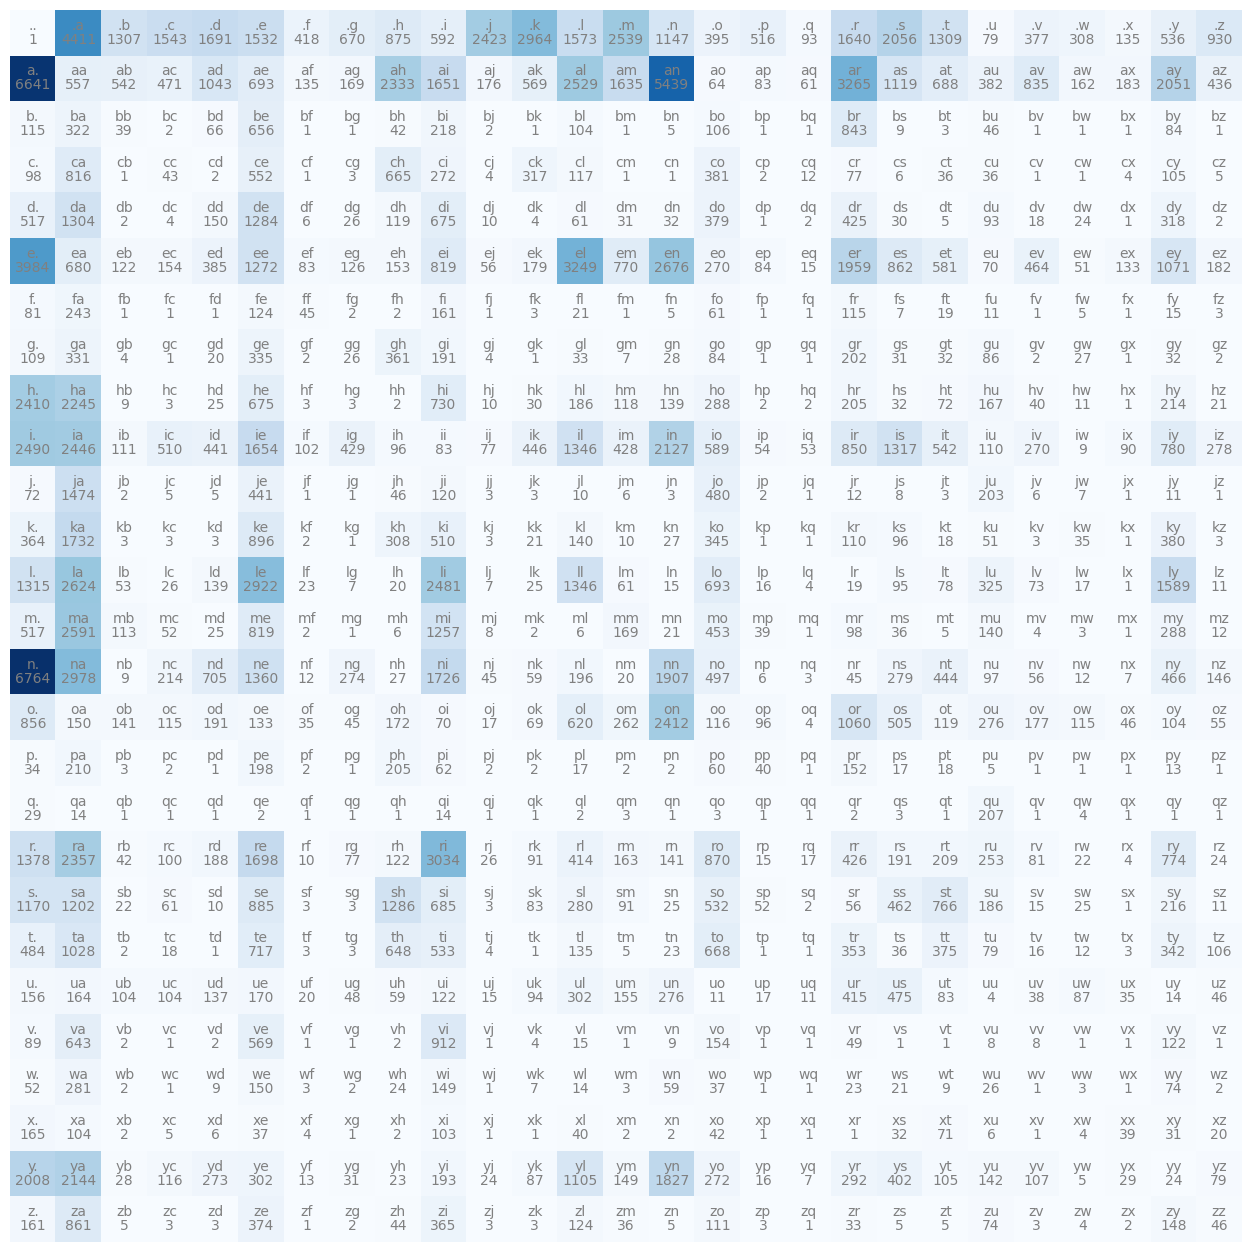

In [464]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(A, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itoc[i] + itoc[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, A[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [465]:
A[0]

tensor([   1, 4411, 1307, 1543, 1691, 1532,  418,  670,  875,  592, 2423, 2964,
        1573, 2539, 1147,  395,  516,   93, 1640, 2056, 1309,   79,  377,  308,
         135,  536,  930], dtype=torch.int32)

In [466]:
p = A[0].float()
p = p / p.sum()
p

tensor([3.1192e-05, 1.3759e-01, 4.0767e-02, 4.8129e-02, 5.2745e-02, 4.7785e-02,
        1.3038e-02, 2.0898e-02, 2.7293e-02, 1.8465e-02, 7.5577e-02, 9.2452e-02,
        4.9064e-02, 7.9195e-02, 3.5777e-02, 1.2321e-02, 1.6095e-02, 2.9008e-03,
        5.1154e-02, 6.4130e-02, 4.0830e-02, 2.4641e-03, 1.1759e-02, 9.6070e-03,
        4.2109e-03, 1.6719e-02, 2.9008e-02])

In [467]:
normalized_A = torch.zeros(len(A), len(A[0]))

for i in range(len(A)):
    row = A[i].float()
    normalized_A[i] = row/row.sum()
normalized_A

tensor([[3.1192e-05, 1.3759e-01, 4.0767e-02, 4.8129e-02, 5.2745e-02, 4.7785e-02,
         1.3038e-02, 2.0898e-02, 2.7293e-02, 1.8465e-02, 7.5577e-02, 9.2452e-02,
         4.9064e-02, 7.9195e-02, 3.5777e-02, 1.2321e-02, 1.6095e-02, 2.9008e-03,
         5.1154e-02, 6.4130e-02, 4.0830e-02, 2.4641e-03, 1.1759e-02, 9.6070e-03,
         4.2109e-03, 1.6719e-02, 2.9008e-02],
        [1.9583e-01, 1.6425e-02, 1.5983e-02, 1.3889e-02, 3.0756e-02, 2.0435e-02,
         3.9809e-03, 4.9835e-03, 6.8796e-02, 4.8685e-02, 5.1899e-03, 1.6779e-02,
         7.4575e-02, 4.8213e-02, 1.6039e-01, 1.8872e-03, 2.4475e-03, 1.7988e-03,
         9.6279e-02, 3.2997e-02, 2.0288e-02, 1.1264e-02, 2.4623e-02, 4.7771e-03,
         5.3963e-03, 6.0480e-02, 1.2857e-02],
        [4.3039e-02, 1.2051e-01, 1.4596e-02, 7.4850e-04, 2.4701e-02, 2.4551e-01,
         3.7425e-04, 3.7425e-04, 1.5719e-02, 8.1587e-02, 7.4850e-04, 3.7425e-04,
         3.8922e-02, 3.7425e-04, 1.8713e-03, 3.9671e-02, 3.7425e-04, 3.7425e-04,
         3.1549e-

In [468]:
g = torch.Generator().manual_seed(2147483647)

In [469]:
for i in range(20):
    name = []
    row_ix = 0
    while True:
        ix = torch.multinomial(normalized_A[row_ix], num_samples=1, replacement=True, generator=g).item()
    
        if ix == 0:
            break
    
        name.append(itoc[ix])
        row_ix = ix
    print(''.join(name))

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda
ka
emimmsade
enkaviyny
ftlspihinivenvorhlasu
dsor
br
jol
pen
aisan
ja


In [470]:
# What is the average likelihood of every name in the training set being generated?

# In Karpathy's implementation, he takes the average of all the
# log likelihoods. On the other hand, I wanted to take the avg
# log likelihood for all the names.
# Basically, K's impl was:
# (name1 + name2...nameN)/n where nameX = ll1 + ll2+...llY
# Here, N is the number of names, ll is the log likelihood of individual
# probabilities, Y is the number of probabilities in a given name.
# Vs What I wanted to do was:
# (name1/y1 + name2/y2 +...nameN/yN)/N

# I think mine also works but I am not completely sure if that is right.
# Will go ahead with K's impl for now.
log_likelihood = 0
n = 0
for name in names:    
    name = ['.'] + list(name) + ['.']
    for ch1,ch2 in zip(name, name[1:]):
        i1 = ctoi[ch1]
        i2 = ctoi[ch2]
    
        prob = normalized_A[i1][i2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n+=1

nll = -log_likelihood
avg_nll = nll/n
print(f'{log_likelihood=}')
print(f'{avg_nll=}')

log_likelihood=tensor(-559951.5625)
avg_nll=tensor(2.4544)


In [471]:
import torch.nn.functional as F

ips = []
ops = []

for name in names:
    name = ['.'] + list(name) + ['.']
    for ch1,ch2 in zip(name, name[1:]):
        i1 = ctoi[ch1]
        i2 = ctoi[ch2]
        ips.append(i1)
        ops.append(i2)

ips_one_hot = F.one_hot(torch.tensor(ips), num_classes=27).float()
ops_one_hot = F.one_hot(torch.tensor(ops), num_classes=27).float()

In [472]:
ips
ops

[5,
 13,
 13,
 1,
 0,
 15,
 12,
 9,
 22,
 9,
 1,
 0,
 1,
 22,
 1,
 0,
 9,
 19,
 1,
 2,
 5,
 12,
 12,
 1,
 0,
 19,
 15,
 16,
 8,
 9,
 1,
 0,
 3,
 8,
 1,
 18,
 12,
 15,
 20,
 20,
 5,
 0,
 13,
 9,
 1,
 0,
 1,
 13,
 5,
 12,
 9,
 1,
 0,
 8,
 1,
 18,
 16,
 5,
 18,
 0,
 5,
 22,
 5,
 12,
 25,
 14,
 0,
 1,
 2,
 9,
 7,
 1,
 9,
 12,
 0,
 5,
 13,
 9,
 12,
 25,
 0,
 5,
 12,
 9,
 26,
 1,
 2,
 5,
 20,
 8,
 0,
 13,
 9,
 12,
 1,
 0,
 5,
 12,
 12,
 1,
 0,
 1,
 22,
 5,
 18,
 25,
 0,
 19,
 15,
 6,
 9,
 1,
 0,
 3,
 1,
 13,
 9,
 12,
 1,
 0,
 1,
 18,
 9,
 1,
 0,
 19,
 3,
 1,
 18,
 12,
 5,
 20,
 20,
 0,
 22,
 9,
 3,
 20,
 15,
 18,
 9,
 1,
 0,
 13,
 1,
 4,
 9,
 19,
 15,
 14,
 0,
 12,
 21,
 14,
 1,
 0,
 7,
 18,
 1,
 3,
 5,
 0,
 3,
 8,
 12,
 15,
 5,
 0,
 16,
 5,
 14,
 5,
 12,
 15,
 16,
 5,
 0,
 12,
 1,
 25,
 12,
 1,
 0,
 18,
 9,
 12,
 5,
 25,
 0,
 26,
 15,
 5,
 25,
 0,
 14,
 15,
 18,
 1,
 0,
 12,
 9,
 12,
 25,
 0,
 5,
 12,
 5,
 1,
 14,
 15,
 18,
 0,
 8,
 1,
 14,
 14,
 1,
 8,
 0,
 12,
 9,
 12,
 12,
 9,
 1,
 14,
 

In [473]:
# I have the inputs and the outputs.
# I have their one hot formats as well.
# Next, I need to construct the probability matrix from before but this time it will be our matrix and each probability will be our weights.
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [474]:
W.shape

torch.Size([27, 27])

In [475]:
ips_one_hot.shape

torch.Size([228146, 27])

In [476]:
def forward_pass():
    logits = ips_one_hot @ W
    # I've multiplied n*27 with 27*27. Resultant matrix is n*27
    # Every row is made up of logits which are supposed to represent the probability matrix.
    # But these values are negative and have not been normalized either.
    # So, we first turn them into positive, then normalize the entire row i.e. softmax the row.

    exp_logits = logits.exp()
    probs = exp_logits / exp_logits.sum(1, keepdims=True) # probabilities for next character
    avg_nll_aka_loss = -probs[torch.arange(len(ips)), ops].log().mean()

    return avg_nll_aka_loss

In [477]:
def gradient_descent():
    loss = (forward_pass())
    
    W.grad = None
    loss.backward()
    W.data += -50*W.grad
    return loss

In [481]:
total_loss = None
for i in range(100):
    total_loss = gradient_descent()

In [482]:
total_loss.item()

2.47084379196167

In [483]:
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itoc[ix])
    if ix == 0:
      break
  print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.
da.
staiyauelalerigotai.
moliellavo.
ke.
teda.


In [457]:
exp_W = W.exp()
prob_matrix = exp_W / exp_W.sum(1, keepdims=True)
prob_matrix

tensor([[4.1267e-05, 1.3767e-01, 4.0769e-02, 4.8137e-02, 5.2756e-02, 4.7792e-02,
         1.3016e-02, 2.0884e-02, 2.7283e-02, 1.8448e-02, 7.5608e-02, 9.2498e-02,
         4.9074e-02, 7.9231e-02, 3.5774e-02, 1.2299e-02, 1.6076e-02, 2.8705e-03,
         5.1165e-02, 6.4152e-02, 4.0829e-02, 2.4331e-03, 1.1736e-02, 9.5827e-03,
         4.1816e-03, 1.6700e-02, 2.9000e-02],
        [1.9597e-01, 1.6410e-02, 1.5966e-02, 1.3870e-02, 3.0751e-02, 2.0422e-02,
         3.9548e-03, 4.9579e-03, 6.8821e-02, 4.8694e-02, 5.1642e-03, 1.6762e-02,
         7.4603e-02, 4.8222e-02, 1.6047e-01, 1.8595e-03, 2.4201e-03, 1.7707e-03,
         9.6322e-02, 3.2994e-02, 2.0274e-02, 1.1244e-02, 2.4614e-02, 4.7517e-03,
         5.3708e-03, 6.0498e-02, 1.2837e-02],
        [4.2903e-02, 1.2117e-01, 1.4164e-02, 4.6380e-04, 2.4375e-02, 2.4744e-01,
         2.9178e-04, 2.8300e-04, 1.5299e-02, 8.1846e-02, 4.7094e-04, 2.5760e-04,
         3.8744e-02, 3.1181e-04, 1.2332e-03, 3.9500e-02, 3.0037e-04, 3.0902e-04,
         3.1814e-